# Instruct vs finetuned — self-recognition comparison

Base **Llama-3.1-8B-Instruct** vs the **finetuned LoRA** (same base, so this isolates
the finetuning effect). Both are single-model 14-case self-recognition runs where the
model recognizes *its own* generated text.

| model | eval_dir | generations |
|---|---|---|
| instruct | `personacat_v3_eval` | base Llama's own (`personacat_v1`) |
| finetuned | `personacat_lora_eval` | finetuned model's own (`personacat_lora`) |

Both runs are base-Llama-slugged with all 14 cases (the base-instruct 1–12 were merged in from the pre-convention `personacat_v3_eval` folder).

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import sys, pathlib
_root = pathlib.Path.cwd().resolve()
while not (_root / "core").is_dir() and _root != _root.parent:
    _root = _root.parent
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))
import logging; logging.basicConfig(level=logging.INFO)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import experiments.self_recognition.analyze_behavior_helpers as B
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)

MODEL = "meta-llama/Llama-3.1-8B-Instruct"        # both runs share this slug
RUNS = {"instruct": "personacat_v3_eval", "finetuned": "personacat_lora_eval"}   # both base-Llama-slugged, all 14 cases
COLORS = {"instruct": "#DD8452", "finetuned": "#55A868"}   # instruct = orange, finetuned = green (consistent across all plots)

dfs = {}
for name, eval_dir in RUNS.items():
    try:
        dfs[name] = B.load_eval_trials(eval_dir, model=MODEL)
        d = dfs[name]
        print(f"{name:10s} ({eval_dir}): {len(d):,} trials | cases {sorted(d.case_id.unique())}")
    except FileNotFoundError:
        print(f"{name:10s} ({eval_dir}): NOT FOUND — run its eval config first.")
print("\nloaded:", list(dfs))

instruct   (personacat_v3_eval): 42,304 trials | cases ['case1', 'case10', 'case11', 'case12', 'case13', 'case14', 'case2', 'case3', 'case4', 'case5', 'case6', 'case7', 'case8', 'case9']


finetuned  (personacat_lora_eval): 42,304 trials | cases ['case1', 'case10', 'case11', 'case12', 'case13', 'case14', 'case2', 'case3', 'case4', 'case5', 'case6', 'case7', 'case8', 'case9']

loaded: ['instruct', 'finetuned']


## 1 · Active surplus over the best neutral decoder — instruct vs finetuned

`case7(active) − max(case6, case13, case14)` by persona category, for each model.
Grouped diverging bars, two-proportion 95% CI. The introspection signal (if any) lives
in **suppression / near_twin**. A model with a higher bar there recognizes its own text
beyond what content inference / style supports.

,model,evaluator_coarse,acc_active,best_neutral_case,acc_best_neutral,surplus,surplus_lo,surplus_hi
0,instruct,calibration,0.747,case6,0.686,0.061,0.002,0.120
1,instruct,confound,0.756,case6,0.787,-0.030,-0.109,0.048
2,instruct,near_twin,0.570,case6,0.655,-0.084,-0.137,-0.032
3,instruct,neutral,0.612,case6,0.630,-0.018,-0.067,0.031
4,instruct,suppression,0.594,case6,0.556,0.038,-0.007,0.083
5,finetuned,calibration,0.771,case6,0.654,0.117,0.058,0.176
6,finetuned,confound,0.741,case6,0.775,-0.034,-0.114,0.046
7,finetuned,near_twin,0.578,case6,0.664,-0.086,-0.139,-0.034
8,finetuned,neutral,0.618,case6,0.646,-0.028,-0.076,0.021
9,finetuned,suppression,0.596,case14,0.544,0.053,0.007,0.098


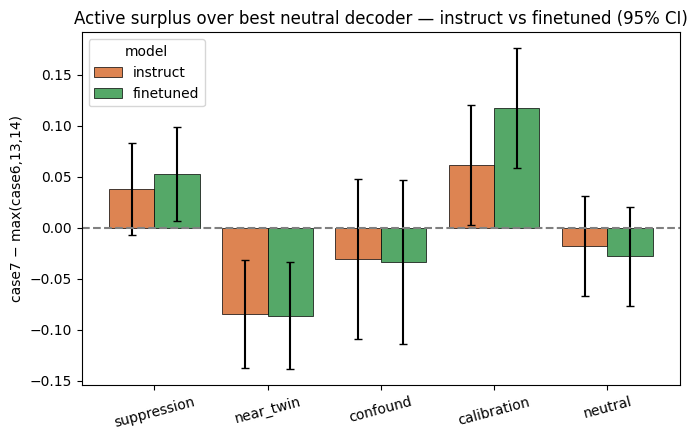

In [2]:
CAT_ORDER = ["suppression","near_twin","confound","calibration","neutral"]
rows = []
for name, d in dfs.items():
    b = B.active_minus_best_neutral(d, by="evaluator_coarse")
    if b.empty:
        print(f"{name}: can't compute (needs case7 + a neutral case). Cases present: {sorted(d.case_id.unique())}")
        continue
    b["model"] = name
    rows.append(b)
if rows:
    comp = pd.concat(rows, ignore_index=True)
    display(comp[["model","evaluator_coarse","acc_active","best_neutral_case","acc_best_neutral",
                  "surplus","surplus_lo","surplus_hi"]].round(3))
    # grouped diverging bars: category × model
    cats = [c for c in CAT_ORDER if c in comp.evaluator_coarse.unique()]
    models = [m for m in RUNS if m in comp.model.unique()]
    x = np.arange(len(cats)); w = 0.8/max(1,len(models))
    fig, ax = plt.subplots(figsize=(max(7,1.4*len(cats)),4.5))
    for j,m in enumerate(models):
        sub = comp[comp.model==m].set_index("evaluator_coarse").reindex(cats)
        val = sub.surplus.to_numpy()
        lo = np.clip(np.nan_to_num(val - sub.surplus_lo.to_numpy()),0,None)
        hi = np.clip(np.nan_to_num(sub.surplus_hi.to_numpy() - val),0,None)
        ax.bar(x+j*w, val, w, yerr=[lo,hi], capsize=3, label=m, color=COLORS.get(m), edgecolor="black", linewidth=0.5)
    ax.axhline(0, ls="--", c="gray"); ax.set_xticks(x+w*(len(models)-1)/2); ax.set_xticklabels(cats, rotation=15)
    ax.set_ylabel("case7 − max(case6,13,14)"); ax.legend(title="model")
    ax.set_title("Active surplus over best neutral decoder — instruct vs finetuned (95% CI)")
    plt.tight_layout(); plt.show()
else:
    print("Neither model has case7 + neutral cases yet.")

## 2 · Framing-matched ladder (case 7 / 13 / 14) by category — both models

The three pick-one cases side by side per category, per model: case 7 (active,
introspection), case 13 (neutral, both described = content ceiling), case 14 (neutral,
redacted = style floor). Lets you see whether finetuning moved case 7, the neutral
baselines, or both.


case7 (active) accuracy by category:


model,finetuned,instruct
evaluator_coarse,,
suppression,0.596,0.594
near_twin,0.578,0.570
confound,0.741,0.756
calibration,0.771,0.747
neutral,0.618,0.612


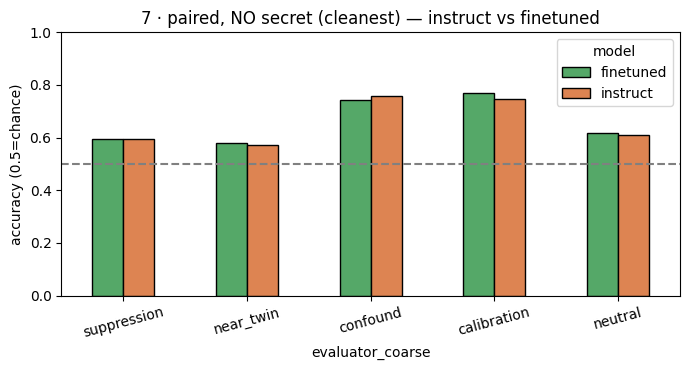


case13 (neutral) accuracy by category:


model,finetuned,instruct
evaluator_coarse,,
suppression,0.495,0.493
near_twin,0.566,0.568
confound,0.534,0.491
calibration,0.549,0.542
neutral,0.537,0.521


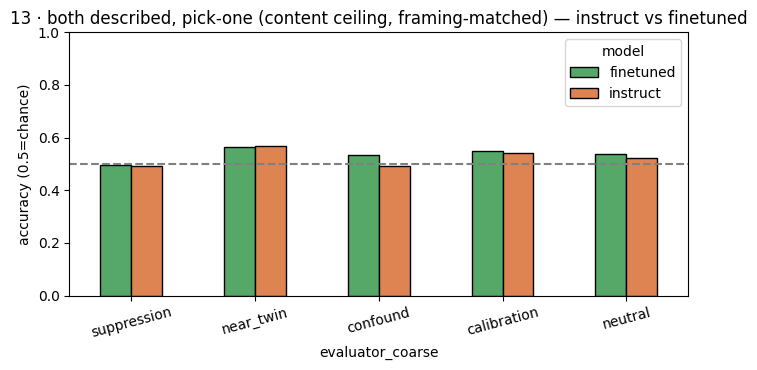


case14 (neutral) accuracy by category:


model,finetuned,instruct
evaluator_coarse,,
suppression,0.544,0.539
near_twin,0.537,0.514
confound,0.521,0.479
calibration,0.571,0.560
neutral,0.525,0.517


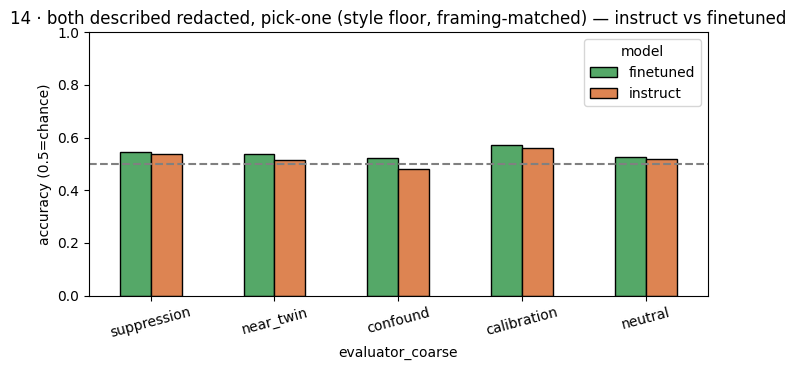

In [3]:
for cid in ["case7","case13","case14"]:
    cond = "active" if cid=="case7" else "neutral"
    rows=[]
    for name,d in dfs.items():
        t = B.accuracy_table(d[(d.case_id==cid)&(d.condition==cond)], by="evaluator_coarse")
        if t.empty: continue
        t["model"]=name; rows.append(t)
    if not rows:
        print(f"{cid}: no data in either run yet"); continue
    t = pd.concat(rows, ignore_index=True)
    piv = t.pivot_table(index="evaluator_coarse", columns="model", values="accuracy", observed=True).reindex(CAT_ORDER).dropna(how="all")
    print(f"\n{cid} ({cond}) accuracy by category:"); display(piv.round(3))
    ax = piv.plot(kind="bar", figsize=(7,3.8), color=[COLORS.get(m) for m in piv.columns], edgecolor="black")
    ax.axhline(0.5, ls="--", c="gray"); ax.set_ylim(0,1); ax.set_ylabel("accuracy (0.5=chance)")
    ax.set_title(f"{B.CASE_LABELS.get(cid,cid)} — instruct vs finetuned"); plt.xticks(rotation=15)
    plt.tight_layout(); plt.show()

## 3 · Per-case overall accuracy — instruct vs finetuned

Every case's overall accuracy (native condition), both models side by side. A compact
scan of where finetuning changed self-recognition behavior across the whole ladder.

In [4]:
rows=[]
for name,d in dfs.items():
    ov = B.case_overview(d)   # per (case, condition) accuracy
    ov = ov[ov.condition==ov.condition]  # keep all
    ov["model"]=name; rows.append(ov)
if rows:
    ovc = pd.concat(rows, ignore_index=True)
    piv = ovc.pivot_table(index=["case_id","condition"], columns="model", values="accuracy", observed=True)
    display(piv.round(3))

model              finetuned  instruct
case_id condition                     
case1   active         0.534     0.537
case10  neutral        0.502     0.513
case11  active         0.571     0.569
case12  active         0.947     0.941
        neutral        0.500     0.500
case13  neutral        0.533     0.524
case14  neutral        0.540     0.527
case2   active         0.558     0.559
case3   active         0.576     0.587
case4   active         0.535     0.563
case5   active         0.564     0.539
        neutral        0.545     0.508
case6   neutral        0.626     0.634
case7   active         0.634     0.627
case8   neutral        0.549     0.530
case9   neutral        0.557     0.531